# Eksplorativna analiza podataka (EDA)

**Izvor podataka:** tabela `ml_dataset` iz MySQL baze, izvezena skriptom `src/kp_classifier/data/export_mysql.py` u `data/raw/ml_dataset.parquet`.

**Cilj ove analize** je da pre izbora arhitekture razumemo podatke:

1. strukturu tabele i odnos između grupa i kategorija,
2. kvalitet podataka: nedostajuće vrednosti, duplikati i naslovi koji se javljaju u više grupa,
3. dužinu naslova, na osnovu koje biramo maksimalnu dužinu ulazne sekvence,
4. karakteristike teksta: pismo, dijakritici, cifre, velika slova, simboli, brojevi telefona,
5. veličinu i raspodelu vokabulara, na osnovu kojih biramo veličinu rečnika i tokenizaciju,
6. sličnost grupa, odnosno koje klase će modelu biti najteže da razlikuje.

Grafici se čuvaju u `reports/figures/` i koriste se u izveštaju.

## 1. Učitavanje podataka

Učitavamo izvezeni parquet fajl i podešavamo putanje. Notebook radi i kada je radni direktorijum `notebooks/` i kada je koren projekta.

In [1]:
import re
import unicodedata
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet(ROOT / "data" / "raw" / "ml_dataset.parquet")
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
df.head(10)

,category_id,group_id,category_name,group_name,name
0,23,489,Mobilni telefoni,Apple iPhone,iPhone 8 64gb BH 85% DOBAR
1,23,489,Mobilni telefoni,Apple iPhone,iphone 14 yellow 128gb
2,23,489,Mobilni telefoni,Apple iPhone,OTKUP iPhone 11 Pro / Pro Max
3,23,489,Mobilni telefoni,Apple iPhone,Apple iPhone 15 128GB Black
4,23,489,Mobilni telefoni,Apple iPhone,iPhone 11 Pro 64gb otvoren na sve mreze (sim-free)
5,23,489,Mobilni telefoni,Apple iPhone,(Rezervisan)iPhone 6s 128GB 100%BH TOP STANJE
6,23,489,Mobilni telefoni,Apple iPhone,iphone 13 pro
7,23,489,Mobilni telefoni,Apple iPhone,Iphone 16 Pro 128 / 16 Pro 256 - NA STANJU!
8,23,489,Mobilni telefoni,Apple iPhone,iphone 11 pro
9,23,489,Mobilni telefoni,Apple iPhone,OTKUP APPLE IPHONE SE 2022 kupujem 065/280-20-20


## 2. Osnovne informacije

Proveravamo dimenzije tabele, tipove kolona, nedostajuće vrednosti i prazne naslove.

Tabela ima pet kolona:

| kolona | uloga |
|---|---|
| `name` | naziv oglasa, **jedini ulaz u model** |
| `group_id`, `group_name` | **ciljna klasa** |
| `category_id`, `category_name` | nadređena kategorija grupe |

In [2]:
print("Oblik:", df.shape)
print("\nTipovi:\n", df.dtypes)
print("\nNedostajuće vrednosti:\n", df.isna().sum())
print("\nPrazni naslovi:", (df["name"].astype(str).str.strip() == "").sum())
print("\nBroj jedinstvenih vrednosti:\n", df.nunique())

Oblik: (50000, 5)

Tipovi:
 category_id      int64
group_id         int64
category_name      str
group_name         str
name               str
dtype: object

Nedostajuće vrednosti:
 category_id      0
group_id         0
category_name    0
group_name       0
name             0
dtype: int64

Prazni naslovi: 0

Broj jedinstvenih vrednosti:
 category_id         10
group_id            10
category_name       10
group_name          10
name             42765
dtype: int64


## 3. Grupe i kategorije

Proveravamo raspodelu klasa i odnos između grupa i kategorija. Ako svaka grupa pripada tačno jednoj kategoriji i svaka kategorija sadrži tačno jednu grupu, kategorija ne nosi dodatnu informaciju u odnosu na grupu i ne koristi se ni kao ulaz ni kao pomoćni cilj.

Kategorija se u svakom slučaju ne sme koristiti kao ulaz, jer model u upotrebi dobija samo naziv oglasa.

 group_id                        group_name  category_id                  category_name  count
      489                      Apple iPhone           23               Mobilni telefoni   5000
      973              Električne brusilice          969                  Alati i oruđa   5000
      405                  Kreveti i dušeci         1268                       Nameštaj   5000
     1277 Motokultivatori | Delovi i oprema          501                  Poljoprivreda   5000
      232               Placevi i zemljište           26       Nekretnine | Kupoprodaja   5000
     1142                   Plišane igračke         1157                 Igračke i igre   5000
     2663       Roštilji, grilovi i friteze           15   Bela tehnika i kućni aparati   5000
     2173 Samsung | Futrole, maske i folije         1017 Mobilni tel. | Oprema i delovi   5000
      589                  Sličice i albumi          584                Kolekcionarstvo   5000
      769      Upaljači, tabakere i pljoske       

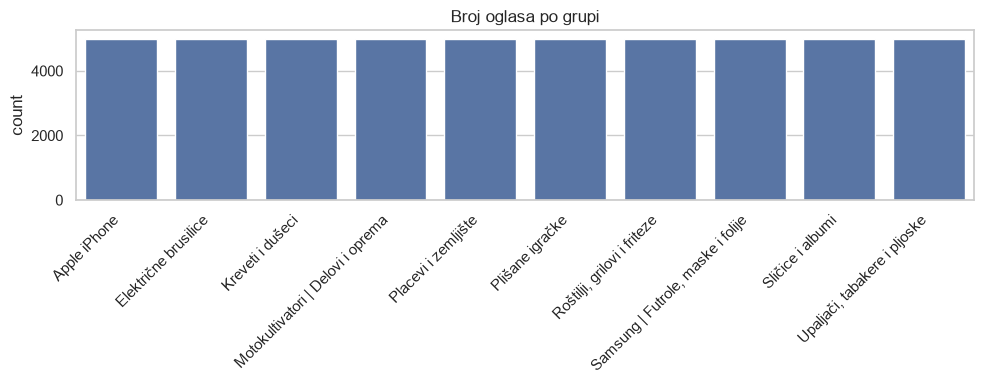

In [3]:
groups = (
    df.groupby(["group_id", "group_name", "category_id", "category_name"])
    .size()
    .reset_index(name="count")
    .sort_values("group_name")
)
print(groups.to_string(index=False))

groups_per_category = df.groupby("category_id")["group_id"].nunique()
categories_per_group = df.groupby("group_id")["category_id"].nunique()
print("\nMapiranje grupa <-> kategorija je 1:1:",
      bool((groups_per_category == 1).all() and (categories_per_group == 1).all()))

plt.figure(figsize=(10, 4))
sns.barplot(data=groups, x="group_name", y="count")
plt.xticks(rotation=45, ha="right")
plt.title("Broj oglasa po grupi")
plt.xlabel("")
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_class_distribution.png", dpi=150)
plt.show()

## 4. Duplikati i konflikti između grupa

Ovo je najvažniji deo analize kvaliteta podataka.

- **Duplikati unutar iste grupe**: ako isti naslov završi i u trening i u test skupu, model ga je "već video", pa je izmerena tačnost lažno visoka (*data leakage*). Duplikate treba ukloniti pre podele na skupove.
- **Konflikti**: isti naslov se javlja u više grupa. Takvi primeri su suštinski dvosmisleni i postavljaju gornju granicu tačnosti koju bilo koji model može da postigne.

Naslove poredimo posle osnovne normalizacije: Unicode NFKC, mala slova i sažimanje razmaka.

In [4]:
def normalize(s):
    s = unicodedata.normalize("NFKC", str(s)).lower()
    return re.sub(r"\s+", " ", s).strip()

df["name_norm"] = df["name"].map(normalize)

print("Tačni duplikati naslova:", df.duplicated("name").sum())
print("Duplikati posle normalizacije:", df.duplicated("name_norm").sum())
print("Duplikati (normalizovan naslov + grupa):", df.duplicated(["name_norm", "group_id"]).sum())

dup_by_group = (
    df[df.duplicated(["name_norm", "group_id"], keep="first")]
    .groupby("group_name").size()
    .reindex(sorted(df["group_name"].unique()), fill_value=0)
)
print("\nDuplikati po grupi:\n", dup_by_group.to_string())

conflicts = df.groupby("name_norm")["group_name"].nunique()
conflict_names = conflicts[conflicts > 1].index
print("\nNaslova koji se javljaju u više grupa:", len(conflict_names))
print("Redova pogođenih konfliktom:", df["name_norm"].isin(conflict_names).sum())

Tačni duplikati naslova: 7235
Duplikati posle normalizacije: 7961
Duplikati (normalizovan naslov + grupa): 7954

Duplikati po grupi:
 group_name
Apple iPhone                          339
Električne brusilice                  154
Kreveti i dušeci                     1389
Motokultivatori | Delovi i oprema     408
Placevi i zemljište                   308
Plišane igračke                      1093
Roštilji, grilovi i friteze          1990
Samsung | Futrole, maske i folije      60
Sličice i albumi                      883
Upaljači, tabakere i pljoske         1330

Naslova koji se javljaju u više grupa: 7
Redova pogođenih konfliktom: 22


Primeri naslova koji se javljaju u više grupa:

In [5]:
(
    df[df["name_norm"].isin(conflict_names)]
    .groupby("name_norm")["group_name"]
    .agg(lambda x: sorted(set(x)))
    .head(30)
)

name_norm
kuca                    [Placevi i zemljište, Plišane igračke]
na prodaju                [Kreveti i dušeci, Sličice i albumi]
prodaja                [Električne brusilice, Plišane igračke]
prodajem               [Kreveti i dušeci, Placevi i zemljište]
zippo upaljaci    [Apple iPhone, Upaljači, tabakere i pljoske]
zirafa                 [Električne brusilice, Plišane igračke]
zverici                    [Plišane igračke, Sličice i albumi]
Name: group_name, dtype: object

Najčešće ponovljeni naslovi. Ako su to generički naslovi bez sadržaja (npr. "prodajem", "povoljno"), model iz njih ne može ništa da nauči.

In [6]:
df["name_norm"].value_counts().head(20)

name_norm
krevet                   298
plac                      94
francuski lezaj           89
friteza                   77
francuski ležaj           46
bračni krevet             45
dusek                     43
bracni krevet             42
krevet samac              39
spavaca soba              35
plac na prodaju           32
dušek                     30
deciji krevet             30
krevet na sprat           28
kreveti                   28
upaljac                   28
krevet na rasklapanje     22
friteza na paru           22
iphone 11                 21
prodajem plac             21
Name: count, dtype: int64

Prikazu raspodelE klasa posle deduplikacije i uklanjanja konflikata

                                    pre  posle  uklonjeno_%
group_name                                                 
Roštilji, grilovi i friteze        5000   3010         39.8
Kreveti i dušeci                   5000   3609         27.8
Upaljači, tabakere i pljoske       5000   3669         26.6
Plišane igračke                    5000   3903         21.9
Sličice i albumi                   5000   4115         17.7
Motokultivatori | Delovi i oprema  5000   4592          8.2
Apple iPhone                       5000   4660          6.8
Placevi i zemljište                5000   4690          6.2
Električne brusilice               5000   4844          3.1
Samsung | Futrole, maske i folije  5000   4940          1.2

Ukupno posle čišćenja: 42032


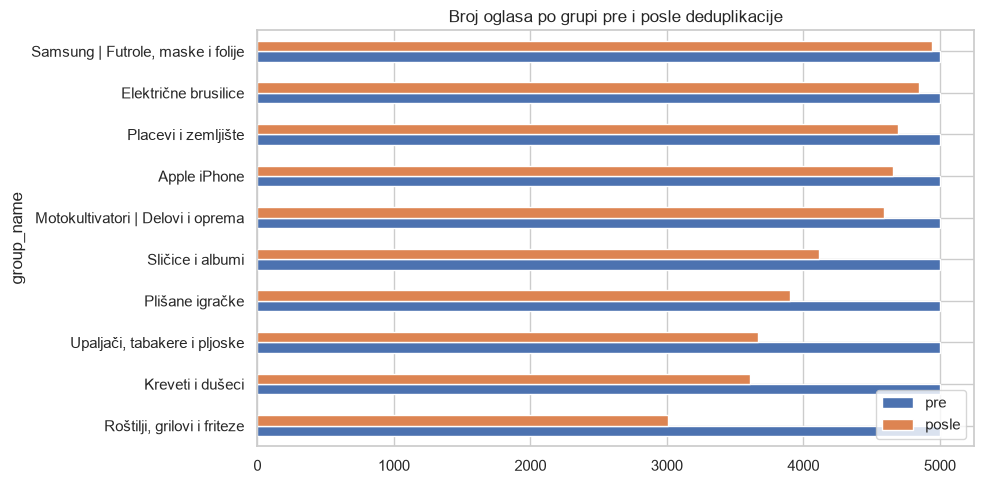

In [7]:
clean = df[~df["name_norm"].isin(conflict_names)].drop_duplicates(["name_norm", "group_id"])
after = clean.groupby("group_name").size().rename("posle")
before = df.groupby("group_name").size().rename("pre")
balance = pd.concat([before, after], axis=1)
balance["uklonjeno_%"] = ((1 - balance["posle"] / balance["pre"]) * 100).round(1)
print(balance.sort_values("posle").to_string())
print("\nUkupno posle čišćenja:", len(clean))

balance[["pre", "posle"]].sort_values("posle").plot(kind="barh", figsize=(10, 5))
plt.title("Broj oglasa po grupi pre i posle deduplikacije")
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_class_balance_after_dedup.png", dpi=150)
plt.show()

## 5. Dužina naslova

Raspodela dužine naslova u karakterima i rečima određuje maksimalnu dužinu ulazne sekvence. Biramo vrednost koja pokriva oko 99% naslova, kako bi odsecanje uticalo na mali broj primera, a padding ne bi nepotrebno trošio memoriju.

Upoređujemo i dužinu po grupama: ako se grupe jako razlikuju po dužini, dužina sama nosi deo informacije o klasi.

        n_chars   n_words
count  50000.00  50000.00
mean      34.44      5.70
std       14.77      2.62
min        2.00      1.00
50%       34.00      5.00
90%       56.00      9.00
95%       59.00     10.00
99%       60.00     12.00
max       60.00     19.00


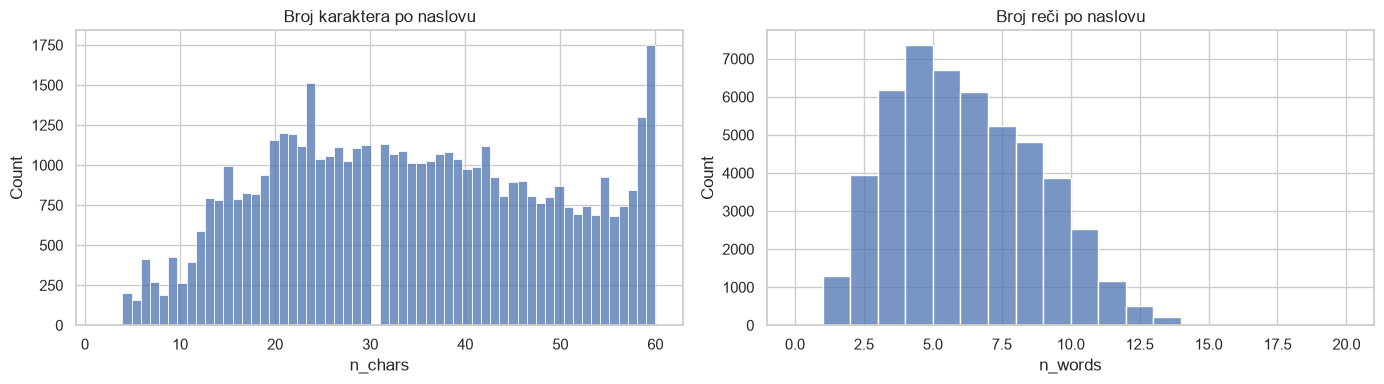

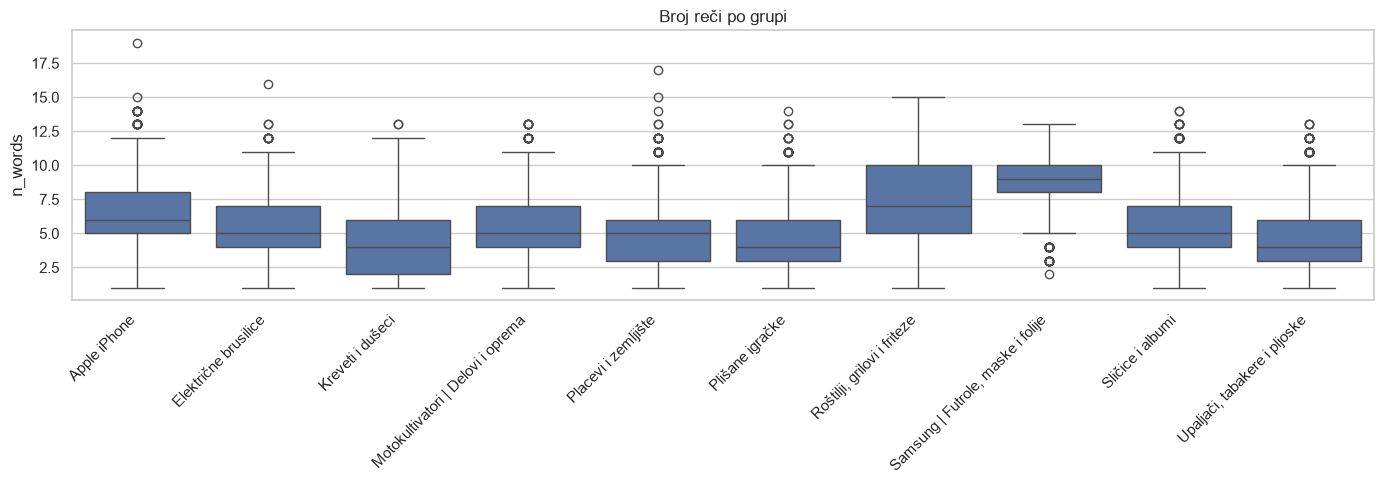

In [8]:
df["n_chars"] = df["name"].astype(str).str.len()
df["n_words"] = df["name_norm"].str.split().str.len()

print(df[["n_chars", "n_words"]].describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df["n_chars"], bins=60, ax=axes[0])
axes[0].set_title("Broj karaktera po naslovu")
sns.histplot(df["n_words"], bins=range(0, int(df["n_words"].max()) + 2), ax=axes[1])
axes[1].set_title("Broj reči po naslovu")
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_length_hist.png", dpi=150)
plt.show()

plt.figure(figsize=(14, 5))
sns.boxplot(data=df, x="group_name", y="n_words")
plt.xticks(rotation=45, ha="right")
plt.title("Broj reči po grupi")
plt.xlabel("")
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_length_by_group.png", dpi=150)
plt.show()

## 6. Karakteristike teksta

Za svaki naslov merimo:

- **ćirilicu**: ako je ima u značajnoj meri, treba je presloviti u latinicu da isti pojam ne bi imao dva zapisa,
- **dijakritike** (č, ć, ž, š, đ): korisnici ih često izostavljaju, pa "dusek" i "dušek" treba svesti na isti oblik,
- **cifre**: modeli telefona, kapaciteti, dimenzije; nose informaciju, ali povećavaju vokabular,
- **udeo velikih slova**: "NA STANJU!" i "na stanju" treba da budu isto,
- **simbole i emotikone**,
- **brojeve telefona**: šum koji ne nosi informaciju o grupi.

In [9]:
PHONE_RE = re.compile(r"(\+?381|0)\s?6\d[\s/\-]?\d{2,4}[\s/\-]?\d{2,4}([\s/\-]?\d{2,4})?")

def char_stats(s):
    s = str(s)
    letters = [c for c in s if c.isalpha()]
    n = max(len(letters), 1)
    return pd.Series({
        "has_cyrillic": any("\u0400" <= c <= "\u04FF" for c in s),
        "has_diacritics": any(c in "čćžšđČĆŽŠĐ" for c in s),
        "has_digit": any(c.isdigit() for c in s),
        "upper_ratio": sum(c.isupper() for c in letters) / n,
        "has_symbol": any(unicodedata.category(c).startswith("S") for c in s),
        "has_phone": bool(PHONE_RE.search(s)),
    })

cs = df["name"].apply(char_stats)
df = pd.concat([df, cs], axis=1)

summary = df.groupby("group_name")[cs.columns].mean().round(3)
summary.loc["UKUPNO"] = df[cs.columns].mean().round(3)
summary

,has_cyrillic,has_diacritics,has_digit,upper_ratio,has_symbol,has_phone
group_name,,,,,,
Apple iPhone,0.000,0.019,0.942,0.285,0.019,0.072
Električne brusilice,0.001,0.174,0.820,0.218,0.019,0.007
Kreveti i dušeci,0.002,0.330,0.356,0.121,0.013,0.001
Motokultivatori | Delovi i oprema,0.000,0.185,0.811,0.169,0.009,0.000
Placevi i zemljište,0.003,0.396,0.667,0.128,0.002,0.002
Plišane igračke,0.001,0.233,0.375,0.154,0.006,0.000
"Roštilji, grilovi i friteze",0.000,0.150,0.883,0.281,0.012,0.000
"Samsung | Futrole, maske i folije",0.000,0.058,0.984,0.201,0.016,0.000
Sličice i albumi,0.001,0.147,0.720,0.116,0.016,0.000


Primeri naslova sa ćirilicom, simbolima i brojevima telefona:

In [10]:
for col in ["has_cyrillic", "has_symbol", "has_phone"]:
    sub = df[df[col]]
    print(f"\n=== {col} ({len(sub)}) ===")
    for s in sub["name"].head(10):
        print("  ", s)


=== has_cyrillic (43) ===
   Додаци за угаону брусилицу
   Parkside diskovi set za secenje Ф89
   Daewoo vibraciona brusilica 113х225, 380W DAOS380
   Daewoo tračna brusilica 76х533, 950W DABS950
   Daewoo vibraciona brusilica 90х187 180W DAOS180
   Кревети од масива буква
   Кревет
   Метални кревет самац
   Француски лежај
   Два дечија кревета 200 х 90 цм са душецима

=== has_symbol (640) ===
   iPhone 11 12 15 15+ 15 + 15 Plus128 256 512
   iPhone 15 Plus 15+ 15 + 512GB Blue
   Apple iPhone XS 64GB+Garancija
   Iphone 13 mini 128gb,sim free,midnight,ful+poklon
   Apple iPhone 8 64GB+Garancija
   Iphone 15+ (plus) - NOV, NEOTPAKOVAN
   Iphone 7plus/+ kuciste
   Iphone 8 + plus
   Apple Ipad Air 5 WiFi+Cellular 64GB
   iPhone 12 128gb - 9,9/10 + maskice i kabl (rezervisan)

=== has_phone (410) ===
   OTKUP APPLE IPHONE SE 2022 kupujem   065/280-20-20
   OTKUP APPLE IPHONE 11 pro kupujem   065/280-20-20
   OTKUP IPHONE 14 pro 256gb kupujem    065/280-20-20
   Otkup iPhone 15proMax 06

## 7. Najčešći tokeni po grupi

Tokenizujemo naslove na reči (niz alfanumeričkih karaktera) i za svaku grupu prikazujemo najčešće tokene. Tako vidimo koje reči su jaki indikatori klase i koje se ponavljaju u više grupa, poput "prodajem", "nov" ili "povoljno".

In [11]:
TOKEN_RE = re.compile(r"\w+", re.UNICODE)
df["tokens"] = df["name_norm"].map(TOKEN_RE.findall)

for g, sub in df.groupby("group_name"):
    c = Counter(t for toks in sub["tokens"] for t in toks)
    print(f"\n=== {g} ===")
    print(", ".join(f"{t}({n})" for t, n in c.most_common(25)))


=== Apple iPhone ===
iphone(4528), pro(1985), apple(1204), 128gb(1148), max(996), otkup(895), 15(825), 256gb(763), 14(752), 13(744), i(587), 11(586), 12(560), 64gb(467), 16(425), black(416), nov(375), akcija(375), novo(366), titanium(318), za(305), telefona(295), garancija(294), plus(293), 512gb(275)

=== Električne brusilice ===
brusilica(2865), ugaona(997), za(910), makita(617), bosch(510), 125(352), sa(292), metabo(276), 125mm(243), brusilicu(243), w(239), vibraciona(209), brusni(203), tocilo(201), novo(190), villager(174), i(162), dewalt(157), vln(152), black(143), gws(140), set(137), papir(135), iskra(132), disk(131)

=== Kreveti i dušeci ===
krevet(2486), na(703), dusek(568), dušek(535), kreveti(471), francuski(460), sa(458), za(441), od(327), lezaj(309), naduvavanje(302), i(269), metala(230), bracni(215), ležaj(210), cm(210), novo(206), sprat(205), bračni(176), metalni(166), akcija(161), x(143), samac(130), 90x200(130), 160x200(119)

=== Motokultivatori | Delovi i oprema ===
im

Tokeni koji se javljaju u najvećem broju grupa. To su kandidati za reči koje modelu ne pomažu, mada ih ne uklanjamo ručno, jer model sam uči da im da malu težinu.

In [12]:
token_groups = (
    df[["group_name", "tokens"]]
    .explode("tokens")
    .dropna()
    .groupby("tokens")["group_name"]
    .nunique()
    .sort_values(ascending=False)
)
token_freq = df["tokens"].explode().value_counts()
pd.DataFrame({"broj_grupa": token_groups, "frekvencija": token_freq}).dropna().sort_values(
    ["broj_grupa", "frekvencija"], ascending=False
).head(30)

,broj_grupa,frekvencija
tokens,,
za,10,7260
na,10,2820
i,10,2504
sa,10,2234
u,10,1604
novo,10,1372
5,10,1123
2,10,1071
15,10,941


## 8. Veličina vokabulara

Brojimo jedinstvene tokene i koliko ih se javlja samo jednom (*hapax legomena*). Veliki broj retkih tokena (pogrešno napisane reči, modeli uređaja, šifre) znači da tokenizacija samo na nivou reči ostavlja mnogo nepoznatih reči. To je argument za karakterske n-grame ili subword tokenizaciju, koje su otporne na greške u kucanju.

Kriva pokrivenosti pokazuje koliko najčešćih tokena pokriva određeni procenat svih pojavljivanja, na osnovu čega biramo veličinu rečnika.

Ukupno tokena: 292638
Jedinstvenih tokena: 24741
Tokena koji se javljaju 1 put: 11693
Tokena sa >= 2 pojavljivanja: 13048
Tokena sa >= 5 pojavljivanja: 5634
Top 1000 tokena pokriva 69.60% pojavljivanja
Top 5000 tokena pokriva 88.42% pojavljivanja
Top 10000 tokena pokriva 93.92% pojavljivanja
Top 20000 tokena pokriva 98.38% pojavljivanja


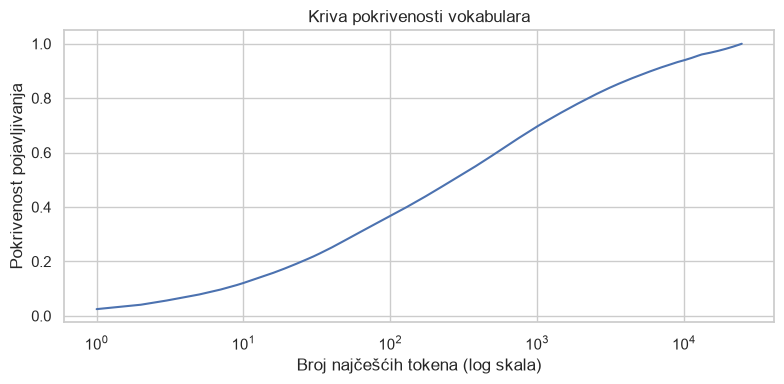

In [13]:
all_counts = Counter(t for toks in df["tokens"] for t in toks)
freqs = np.array(list(all_counts.values()))

print("Ukupno tokena:", int(freqs.sum()))
print("Jedinstvenih tokena:", len(all_counts))
print("Tokena koji se javljaju 1 put:", int((freqs == 1).sum()))
print("Tokena sa >= 2 pojavljivanja:", int((freqs >= 2).sum()))
print("Tokena sa >= 5 pojavljivanja:", int((freqs >= 5).sum()))

sorted_f = np.sort(freqs)[::-1]
coverage = np.cumsum(sorted_f) / sorted_f.sum()
for k in [1000, 5000, 10000, 20000]:
    if k <= len(coverage):
        print(f"Top {k} tokena pokriva {coverage[k-1]*100:.2f}% pojavljivanja")

plt.figure(figsize=(8, 4))
plt.plot(np.arange(1, len(coverage) + 1), coverage)
plt.xscale("log")
plt.xlabel("Broj najčešćih tokena (log skala)")
plt.ylabel("Pokrivenost pojavljivanja")
plt.title("Kriva pokrivenosti vokabulara")
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_vocab_coverage.png", dpi=150)
plt.show()

## 9. Sličnost vokabulara između grupa

Za svaku grupu pravimo skup tokena (samo tokeni sa bar 3 pojavljivanja u celom skupu, da retke reči ne bi kvarile poređenje) i računamo Jaccard sličnost između svakog para grupa:

$$J(A, B) = \frac{|A \cap B|}{|A \cup B|}$$

Parovi sa visokom sličnošću su oni koje će model najteže razlikovati. Očekujemo da se izdvoji par **Apple iPhone** i **Samsung | Futrole, maske i folije**, jer oba sadrže nazive modela telefona.

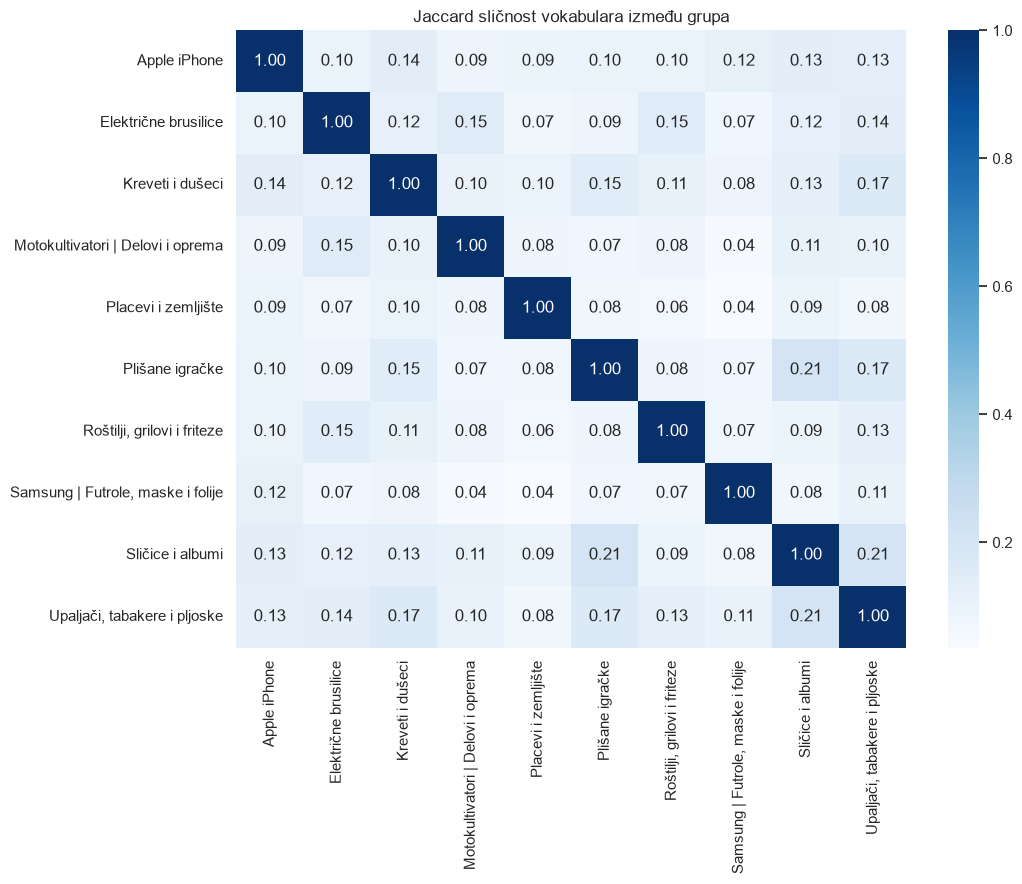

,grupa_a,grupa_b,jaccard
44,Sličice i albumi,"Upaljači, tabakere i pljoske",0.206636
37,Plišane igračke,Sličice i albumi,0.205269
23,Kreveti i dušeci,"Upaljači, tabakere i pljoske",0.167295
38,Plišane igračke,"Upaljači, tabakere i pljoske",0.167112
10,Električne brusilice,Motokultivatori | Delovi i oprema,0.151105
19,Kreveti i dušeci,Plišane igračke,0.147975
13,Električne brusilice,"Roštilji, grilovi i friteze",0.146141
1,Apple iPhone,Kreveti i dušeci,0.137166
16,Električne brusilice,"Upaljači, tabakere i pljoske",0.135689
7,Apple iPhone,Sličice i albumi,0.130492


In [14]:
group_vocab = {
    g: set(t for toks in sub["tokens"] for t in toks if all_counts[t] >= 3)
    for g, sub in df.groupby("group_name")
}
names = sorted(group_vocab)
jac = pd.DataFrame(index=names, columns=names, dtype=float)
for a in names:
    for b in names:
        inter = len(group_vocab[a] & group_vocab[b])
        union = len(group_vocab[a] | group_vocab[b])
        jac.loc[a, b] = inter / union if union else 0

plt.figure(figsize=(11, 9))
sns.heatmap(jac, annot=True, fmt=".2f", cmap="Blues")
plt.title("Jaccard sličnost vokabulara između grupa")
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_vocab_jaccard.png", dpi=150)
plt.show()

pairs = [
    (a, b, jac.loc[a, b]) for i, a in enumerate(names) for b in names[i + 1:]
]
pd.DataFrame(pairs, columns=["grupa_a", "grupa_b", "jaccard"]).sort_values("jaccard", ascending=False).head(10)

Provera koliko je svaka rec informativna preko entropije raspodele po grupama

Maksimalna entropija (ravnomerno u 10 grupa): 3.32

30 najčešćih tokena:
           frekvencija  entropija  max_udeo                   dominantna_grupa
tokens                                                                        
za                6583       2.58      0.44  Samsung | Futrole, maske i folije
samsung           4650       0.05      0.99  Samsung | Futrole, maske i folije
iphone            4157       0.01      1.00                       Apple iPhone
plac              3400      -0.00      1.00                Placevi i zemljište
brusilica         2682      -0.00      1.00               Električne brusilice
na                2287       2.69      0.28                Placevi i zemljište
futrola           2175       0.40      0.92  Samsung | Futrole, maske i folije
pro               2064       0.75      0.86                       Apple iPhone
sa                1971       3.10      0.23                   Kreveti i dušeci
galaxy            1953       0.02      1.00  Samsung | Fut

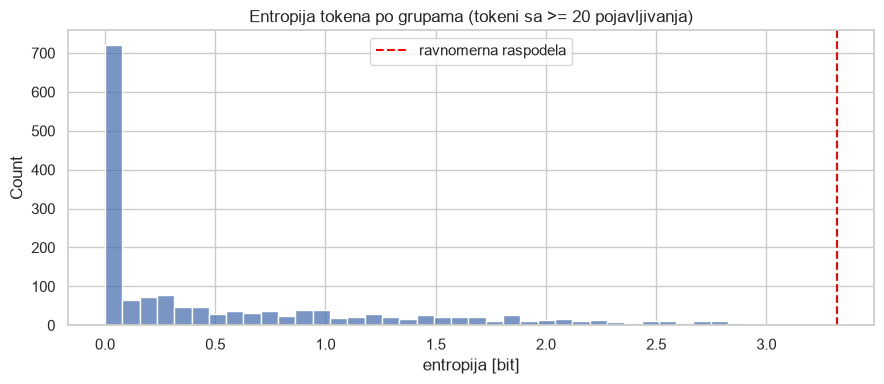


Udeo čestih tokena sa entropijom < 1 bit: 0.764
Udeo čestih tokena sa entropijom > 3 bita: 0.005


In [15]:
clean = clean.copy()
clean["tokens"] = clean["name_norm"].map(TOKEN_RE.findall)

ex = (
    clean[["group_name"]]
    .assign(tokens=clean["tokens"].map(set))
    .explode("tokens")
    .dropna()
    .reset_index(drop=True)
)
ct = pd.crosstab(ex["tokens"], ex["group_name"])
group_sizes = clean["group_name"].value_counts()
rates = ct.div(group_sizes, axis=1)
p = rates.div(rates.sum(axis=1), axis=0)
ent = -(p * np.log2(p.where(p > 0, 1))).sum(axis=1)

token_stats = pd.DataFrame({
    "frekvencija": ct.sum(axis=1),
    "entropija": ent.round(2),
    "max_udeo": p.max(axis=1).round(2),
    "dominantna_grupa": p.idxmax(axis=1),
}).sort_values("frekvencija", ascending=False)

print(f"Maksimalna entropija (ravnomerno u 10 grupa): {np.log2(10):.2f}\n")
print("30 najčešćih tokena:")
print(token_stats.head(30).to_string())

candidates = ["za", "na", "i", "sa", "u", "od", "novo", "nov", "akcija", "super", "komplet", "prodajem", "hitno", "x"]
print("\nKandidati za stop-reči:")
print(token_stats.loc[[t for t in candidates if t in token_stats.index]].to_string())

plt.figure(figsize=(9, 4))
frequent = token_stats[token_stats["frekvencija"] >= 20]
sns.histplot(frequent["entropija"], bins=40)
plt.axvline(np.log2(10), color="red", linestyle="--", label="ravnomerna raspodela")
plt.title("Entropija tokena po grupama (tokeni sa >= 20 pojavljivanja)")
plt.xlabel("entropija [bit]")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_token_entropy.png", dpi=150)
plt.show()

print("\nUdeo čestih tokena sa entropijom < 1 bit:", round((frequent["entropija"] < 1).mean(), 3))
print("Udeo čestih tokena sa entropijom > 3 bita:", round((frequent["entropija"] > 3).mean(), 3))

Za brojeve

In [16]:
def token_type(t):
    if t.isdigit():
        return "broj"
    if any(c.isdigit() for c in t):
        return "slova+cifre"
    return "reč"

token_stats["tip"] = token_stats.index.map(token_type)

type_summary = token_stats.groupby("tip").agg(
    jedinstvenih=("frekvencija", "size"),
    pojavljivanja=("frekvencija", "sum"),
    jednom=("frekvencija", lambda x: int((x == 1).sum())),
    medijana_entropije=("entropija", "median"),
)
type_summary["udeo_jednom_%"] = (type_summary["jednom"] / type_summary["jedinstvenih"] * 100).round(1)
print(type_summary.to_string())

numbers = token_stats[token_stats["tip"] == "broj"]
print("\nNajčešći čisti brojevi i njihova informativnost:")
print(numbers.head(25).to_string())

print("\nInformativni brojevi (frekvencija >= 20, entropija < 1):")
print(numbers[(numbers["frekvencija"] >= 20) & (numbers["entropija"] < 1)].head(25).to_string())

print("\nBroj cifara u čistim brojevima:")
print(numbers.index.str.len().value_counts().sort_index().to_string())

only_numbers = clean["tokens"].map(lambda toks: len(toks) > 0 and all(t.isdigit() for t in toks))
print("\nNaslova sastavljenih samo od brojeva:", int(only_numbers.sum()))
print(clean.loc[only_numbers, ["name", "group_name"]].head(10).to_string())

             jedinstvenih  pojavljivanja  jednom  medijana_entropije  udeo_jednom_%
tip                                                                                
broj                 2291          26369    1332                -0.0           58.1
reč                 16933         195362    8763                -0.0           51.8
slova+cifre          5517          26594    3328                -0.0           60.3

Najčešći čisti brojevi i njihova informativnost:
        frekvencija  entropija  max_udeo                   dominantna_grupa   tip
tokens                                                                           
506             886      -0.00      1.00  Motokultivatori | Delovi i oprema  broj
15              855       0.93      0.87                       Apple iPhone  broj
2               830       3.12      0.23        Roštilji, grilovi i friteze  broj
14              824       1.07      0.83                       Apple iPhone  broj
13              723       0.56      0.

## 10. Nasumični primeri po grupi

Ručni pregled primera je najbrži način da se uoče obrasci koje statistike ne hvataju.

In [17]:
for g, sub in df.groupby("group_name"):
    print(f"\n=== {g} ===")
    for s in sub["name"].sample(8, random_state=42):
        print("  ", s)
        


=== Apple iPhone ===
   Otkup iPhone 12 Lila
   Iphone 14 pro 256gb gold sa apple clear case maskom
   iPhone 11 128GB Purple
   iPhone 14 128Gb / NOV / Garancija
   Samsung Galaxy A55 128GB NOV Garancija 2 Godine
   iPhone 11 Pro 256gb
   iPhone 12 Purple 128GB /PERFEKTAN/
   Apple iPhone 14 Pro Max 512GB Purple

=== Električne brusilice ===
   Pneumatska Womax Bušilica
   Ugaona brusilica mala Bosch GWX 9-125 S 900W X-LOCK 125mm
   INGCO Ugaona el.brusilica 2200W AG220018
   Gama slajferica
   Brusilica za zid VDS 625
   Bosch Gws 14-125 s Professional Corner Brother 1400W
   Festool ETS EC 150/5 EQ Slajferica kao Mirka 2022 God
   VEVOR Preklopiva brusilica za gipsane ploče

=== Kreveti i dušeci ===
   Komode 2 komada
   Latoflex letvice 90x200 2 kom
   Polovan krevet + dusek + naddusek
   Krevet na sprat sa dve fioke i dušek
   Krevet na Sprat  Hit cena
   Krevet za spavanje
   Dušek za decu
   Ikea ,krevet za decu. Malo korišćen, očuvan. Prodaje se s

=== Motokultivatori | Delovi

## 10a. Provera normalizacije na stvarnim podacima

Funkcija `normalize_text` iz `src/kp_classifier/data/preprocess.py` primenjuje se na sve naslove. Proveravamo koliko telefona i šifri oglasa prepoznaje, poredimo je sa jednostavnim detektorom iz sekcije 6 i ručno pregledamo slučajeve u kojima se dva detektora ne slažu.

Takođe merimo koliko dodatnih duplikata nastaje posle pune normalizacije, jer uklanjanje dijakritika i preslovljavanje ćirilice spaja naslove koji su ranije bili različiti.

In [18]:
from kp_classifier.data.preprocess import normalize_text

df["name_clean"] = df["name"].map(normalize_text)
df["has_phone_new"] = df["name_clean"].str.contains("<phone>", regex=False)
df["has_id_new"] = df["name_clean"].str.contains("<id>", regex=False)

print("EDA detektor telefona:", int(df["has_phone"].sum()))
print("Novi detektor telefona:", int(df["has_phone_new"].sum()))
print("Šifre oglasa <id>:", int(df["has_id_new"].sum()))
print("\nPo grupama:")
print(df.groupby("group_name")[["has_phone_new", "has_id_new"]].sum().to_string())

for title, mask in [
    ("Samo EDA detektor (moguće propušteni telefoni)", df["has_phone"] & ~df["has_phone_new"]),
    ("Samo novi detektor", ~df["has_phone"] & df["has_phone_new"]),
]:
    print(f"\n=== {title}: {int(mask.sum())} ===")
    for raw, clean_ in df.loc[mask, ["name", "name_clean"]].head(15).values:
        print(f"  {raw}\n    -> {clean_}")

print("\n=== Primeri <id> ===")
for raw, clean_ in df.loc[df["has_id_new"], ["name", "name_clean"]].head(10).values:
    print(f"  {raw}\n    -> {clean_}")

print("\n=== Nasumični primeri normalizacije ===")
for raw, clean_ in df[["name", "name_clean"]].sample(15, random_state=1).values:
    print(f"  {raw}\n    -> {clean_}")

dup_basic = df.duplicated(["name_norm", "group_id"]).sum()
dup_full = df.duplicated(["name_clean", "group_id"]).sum()
conf_full = df.groupby("name_clean")["group_id"].nunique()
print(f"\nDuplikati posle osnovne normalizacije: {dup_basic}")
print(f"Duplikati posle pune normalizacije: {dup_full} (+{dup_full - dup_basic})")
print(f"Konflikti posle pune normalizacije: {int((conf_full > 1).sum())}")
print(f"Prazni naslovi posle normalizacije: {int((df['name_clean'] == '').sum())}")

EDA detektor telefona: 410
Novi detektor telefona: 382
Šifre oglasa <id>: 213

Po grupama:
                                   has_phone_new  has_id_new
group_name                                                  
Apple iPhone                                 364           0
Električne brusilice                           1           0
Kreveti i dušeci                               4           0
Motokultivatori | Delovi i oprema              0           0
Placevi i zemljište                           10         213
Plišane igračke                                0           0
Roštilji, grilovi i friteze                    1           0
Samsung | Futrole, maske i folije              0           0
Sličice i albumi                               0           0
Upaljači, tabakere i pljoske                   2           0

=== Samo EDA detektor (moguće propušteni telefoni): 33 ===
  Bosch Ugaona brusilica 125mm 720W - GWS 7-125 (0601388108)
    -> bosch ugaona brusilica 125mm 720w gws 7 125 06013

lazni pozitivi se gledaju

In [19]:
mask = df["has_phone_new"] & (df["group_name"] != "Apple iPhone")
for raw, clean_, g in df.loc[mask, ["name", "name_clean", "group_name"]].values:
    print(f"[{g}] {raw}\n    -> {clean_}")

[Električne brusilice] Dve brusilice na prodaju 0641779912
    -> dve brusilice na prodaju <phone>
[Kreveti i dušeci] Fotelja na izvlačenje 117x224x66cm Intex 060508-665
    -> fotelja na izvlacenje 117x224x66cm intex <phone>
[Kreveti i dušeci] Dva ista polovna kauca. Prevoz obezbedjuje kupac. 0653399300
    -> dva ista polovna kauca prevoz obezbedjuje kupac <phone>
[Kreveti i dušeci] Kreveti Više modela 0629642035
    -> kreveti vise modela <phone>
[Kreveti i dušeci] Polovan dusek 200x160, 0644031483 Petar
    -> polovan dusek 200x160 <phone> petar
[Placevi i zemljište] Fantastičan plac na Klisi! 938m2 064/822-21-40
    -> fantastican plac na klisi 938m2 <phone>
[Placevi i zemljište] Prodajem plac u kaluđerici 064/132-70-28
    -> prodajem plac u kaludjerici <phone>
[Placevi i zemljište] Plac u Kaću! 3435m2 064/822-21-40
    -> plac u kacu 3435m2 <phone>
[Placevi i zemljište] Odličan plac u Beočinu! 1000m2 064/822-21-40
    -> odlican plac u beocinu 1000m2 <phone>
[Placevi i zemljište

## 11. Zaključci

### Struktura podataka

- Skup ima **50.000 naslova** u **10 grupa** po 5.000, bez nedostajućih vrednosti i praznih naslova.
- Mapiranje grupa ↔ kategorija je **1:1**: svaka grupa pripada drugoj kategoriji. Kategorija zato ne nosi informaciju dodatnu u odnosu na grupu i **ne koristi se** ni kao ulaz ni kao pomoćni cilj. Kao ulaz je u svakom slučaju neprihvatljiva, jer model u upotrebi dobija samo naziv oglasa.
- Ciljna labela je `group_id` (stabilan identifikator iz baze), mapiran na indeks 0–9 sortiranjem po `group_id`. `group_name` se čuva u `label_map.json` za čitljive izveštaje i izlaz predikcije.

### Duplikati i konflikti

- Posle osnovne normalizacije (NFKC, mala slova, razmaci) ima **7.954 duplikata** (naslov + grupa), odnosno 16% skupa. Raspoređeni su veoma neravnomerno:

| grupa | pre | posle | uklonjeno |
|---|---|---|---|
| Roštilji, grilovi i friteze | 5000 | 3010 | 39,8% |
| Kreveti i dušeci | 5000 | 3609 | 27,8% |
| Upaljači, tabakere i pljoske | 5000 | 3669 | 26,6% |
| Plišane igračke | 5000 | 3903 | 21,9% |
| Sličice i albumi | 5000 | 4115 | 17,7% |
| Motokultivatori, delovi i oprema | 5000 | 4592 | 8,2% |
| Apple iPhone | 5000 | 4660 | 6,8% |
| Placevi i zemljište | 5000 | 4690 | 6,2% |
| Električne brusilice | 5000 | 4844 | 3,1% |
| Samsung, futrole, maske i folije | 5000 | 4940 | 1,2% |

- Duplikati su najčešći u grupama sa kratkim generičkim naslovima ("krevet" 298 puta, "friteza", "upaljac"), a najređi tamo gde naslov skoro uvek sadrži model ili šifru (Samsung futrole, brusilice).
- **Duplikati se uklanjaju pre podele na skupove.** U suprotnom bi isti naslov završio i u trening i u test skupu, pa bi izmerena tačnost bila lažno visoka (*data leakage*). Deduplikacija se radi **posle pune normalizacije** (dijakritici, ćirilica), jer ona otkriva dodatne duplikate ("dušek" = "dusek"), pa će konačan broj biti nešto manji od 42.032.
- Razmotrena alternativa: zadržati duplikate i deliti skup po grupama identičnih naslova (`GroupShuffleSplit`), čime se čuva realna frekvencija naslova. Izabrana je deduplikacija jer daje pošteniju procenu na neviđenim naslovima.
- **Konflikti su zanemarljivi:** samo 7 naslova (22 reda) se javlja u više grupa, i svi su generički ("prodajem", "kuca", "na prodaju"). Uklanjaju se.

### Raspodela klasa posle čišćenja

- Odnos najveće i najmanje klase je 4940 : 3010 ≈ **1,64**. Neravnoteža je blaga, pa težine klasa u funkciji gubitka nisu neophodne. Testiraju se kao eksperiment.
- Pored accuracy, prate se **macro F1**, preciznost i odziv po klasi i konfuziona matrica.

### Dužina naslova

- Prosečno 34,4 karaktera i 5,7 reči; 99. percentil je 60 karaktera i 12 reči.
- Maksimum je tačno **60 karaktera**, što znači da baza odseca naslove na toj dužini (npr. "...Prodaje se s").
- Maksimalna dužina sekvence: **60 karaktera** za karakterski ulaz, **20 tokena** za ulaz na nivou reči (najduži naslov ima 19 reči). Nijedan naslov se ne odseca.

### Karakteristike teksta i normalizacija

| osobina | udeo naslova | odluka |
|---|---|---|
| ćirilica | 0,1% | preslovljavanje u latinicu (jeftino, uklanja dvostruke zapise) |
| dijakritici | 19,5% | svođenje na ASCII: č/ć→c, š→s, ž→z, đ→dj |
| cifre | 68,1% | brojevi se zadržavaju (vidi ispod) |
| velika slova | 18,3% slova | sve u mala slova |
| simboli | 1,3% | uklanjaju se sa interpunkcijom |
| broj telefona | 0,8% | zamena tokenom `<phone>` |

- Ista reč se javlja i sa i bez dijakritika u sličnom broju (`dusek` 568, `dušek` 535; `lezaj` / `ležaj`; `zemljiste` / `zemljište`), pa je uklanjanje dijakritika neophodno.
- U naslovu `113х225` slovo `х` je ćirilično i znači "x", pa se između cifara pretvara u latinično `x`, a ne u `h`.
- **Brojevi telefona su rizik od *shortcut learning*-a:** 7,2% naslova u grupi Apple iPhone sadrži broj telefona, uglavnom isti broj koji ponavljaju otkupljivači. Model bi mogao da nauči da je broj telefona znak za iPhone. Telefoni se zamenjuju tokenom `<phone>`, a šifre oglasa ("Sifra: 528492") tokenom `<id>`.

### Informativnost reči i stop-reči

- Za svaki token izračunata je entropija raspodele po grupama: 0 znači da se javlja samo u jednoj grupi, a log₂(10) ≈ 3,32 da je ravnomerno raspoređen.
- **76,4%** čestih tokena (≥ 20 pojavljivanja) ima entropiju ispod 1 bita, a samo **0,5%** iznad 3 bita. Vokabular je visoko diskriminativan.
- Kandidati za stop-reči nisu neinformativni koliko se intuitivno očekuje:

| token | entropija | dominantna grupa |
|---|---|---|
| `i` | 3,14 | Sličice i albumi (17%) |
| `sa` | 3,10 | Kreveti i dušeci (23%) |
| `novo` | 2,89 | Apple iPhone (25%) |
| `na` | 2,69 | Placevi i zemljište (28%) |
| `za` | 2,58 | Samsung futrole (44%) |
| `u` | 1,91 | Placevi i zemljište (64%) |
| `prodajem` | 1,49 | Placevi i zemljište (60%) |
| `hitno` | 0,95 | Placevi i zemljište (82%) |

- **Stop-reči se ne uklanjaju.** Standardna lista srpskih stop-reči bi uklonila `u`, `na` i `za`, a `u` je 64% vezan za placeve ("plac u Obrenovcu"). Neuronska mreža sama uči da neinformativnim rečima da malu težinu. Varijanta bez stop-reči se proverava ablacijom.
- Pošto veliki broj tokena sam određuje klasu, postoji rizik da model postane zavisan od jedne reči. Zato se u treniranju koristi **word dropout**.

### Brojevi

| tip tokena | jedinstvenih | pojavljivanja | javlja se jednom |
|---|---|---|---|
| reč | 16.933 | 195.362 | 51,8% |
| broj | 2.291 | 26.369 | 58,1% |
| slova + cifre | 5.517 | 26.594 | 60,3% |

- Česti brojevi su među najjačim signalima u skupu: `506` (886 naslova, 100% Motokultivatori, model IMT 506), `125` (98% Električne brusilice, prečnik diska), `11`–`16` (77–93% Apple iPhone, generacije modela).
- Mali brojevi (`1`–`8`) su slab signal (entropija 2,6–3,1).
- Nijedan naslov nije sastavljen samo od brojeva.
- **Brojevi se ne uklanjaju, nego normalizuju:** brojevi sa dovoljnom frekvencijom u **trening skupu** postaju tokeni, a retki se mapiraju u token oblika po broju cifara (`<num1>`, `<num2>`, `<num3>`, `<num4+>`). Mešani tokeni (`128gb`, `125mm`, `s23`) se zadržavaju.

### Vokabular

- **24.741** jedinstvenih tokena, od kojih se **47%** javlja samo jednom (greške u kucanju, šifre delova, modeli uređaja).
- Najčešćih 5.000 tokena pokriva 88,4% pojavljivanja, 10.000 pokriva 93,9%, a 20.000 pokriva 98,4%.
- Dug rep retkih tokena je jak argument za **karakterske n-grame**, koji su otporni na greške u kucanju i nepoznate oblike reči (`brusilica` / `brusilicu` / `brusilice` dele n-grame).

### Sličnost grupa

- Jaccard sličnost vokabulara između grupa je niska: najviše **0,21** (Sličice i albumi ↔ Upaljači, tabakere i pljoske), uglavnom zbog zajedničkih generičkih reči i brojeva.
- Pretpostavka da će par Apple iPhone ↔ Samsung futrole biti najsličniji **nije potvrđena** na nivou vokabulara. Stvarne izvore grešaka pokazaće konfuziona matrica.
- Grupe su leksički dobro razdvojene, pa se očekuje visoka tačnost čak i jednostavnog modela.

### Kvalitet labela

- Ručni pregled nasumičnih primera otkriva pogrešno označene oglase: "Samsung Galaxy A55" u grupi Apple iPhone, "Pneumatska Womax Bušilica" u Električnim brusilicama, "Komode 2 komada" u Krevetima i dušecima, "Na prodaju kuća" u Placevima i zemljištu.
- Tačnost od 100% zato nije dostižna, a analiza grešaka mora da razlikuje greške modela od grešaka u labelama.
- Skup sadrži i naslove na engleskom (`air fryer`, `deep fryer`, `oven`) i španskom (`fichas`, `las`), pa model mora da radi sa mešanim jezikom.

### Plan pripreme podataka

1. NFKC normalizacija
2. Preslovljavanje ćirilice u latinicu
3. Zamena telefona tokenom `<phone>` i šifri oglasa tokenom `<id>`
4. Mala slova i uklanjanje dijakritika
5. Uklanjanje interpunkcije i sažimanje razmaka
6. Deduplikacija i uklanjanje konflikata
7. Stratifikovana podela 80 / 10 / 10 sa fiksnim seed-om
8. Vokabular i normalizacija retkih brojeva **samo na trening skupu**
9. Tokenizacija na reči i karakterske n-grame

### Plan ablacije

Isti model se trenira u više varijanti, a rezultati se porede po macro F1 na validacionom skupu:

| varijanta | promena u odnosu na osnovnu |
|---|---|
| osnovna | svi koraci iznad |
| bez stop-reči | uklonjene najmanje informativne reči |
| bez brojeva | svi čisti brojevi uklonjeni |
| razdvojen broj i jedinica | `128gb` → `128 gb` |
| sa težinama klasa | težine obrnuto proporcionalne veličini klase |
| bez word dropout-a | provera uticaja regularizacije |